<a href="https://colab.research.google.com/github/NadiyaNowshin/Dog-vs-Cat-Image-Classifier/blob/main/Dog_Cat_Image_Classifier_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐶🐱 Dog vs Cat Image Classifier

**Framework:** TensorFlow / Keras  |  **Platform:** Google Colab

This notebook builds and compares three image classifiers on the Dog vs Cat dataset:

1. A **custom CNN** trained from scratch
2. A **feature-extraction model** (frozen pretrained MobileNetV2 + new head)
3. A **fully fine-tuned model** (pretrained EfficientNetB0, all layers trainable)

It finishes with a model comparison and a reusable error-analysis function.

> ⚠️ **Before running:** go to `Runtime → Change runtime type` and select a **GPU** (T4). Training on CPU will be very slow.

In [ ]:
# ---- Imports and global setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score)

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


---
# Dataset Preparation

**Plan:**
- Clone the dataset from GitHub.
- Load the data with `tf.keras.utils.image_dataset_from_directory()`, resizing every image to **224 × 224**.
- Split the training folder into **80% training / 20% validation** using `validation_split` (the same `seed` must be used for both subsets so they don't overlap).
- Keep the test set **unshuffled** so predictions line up with labels later (needed for metrics and error analysis).
- Normalize pixel values from `[0, 255]` to `[0, 1]`, then use `prefetch()` so data loading overlaps with training.

In [ ]:
# Step 1: Download the dataset
!git clone https://github.com/laxmimerit/dog-cat-full-dataset.git

Cloning into 'dog-cat-full-dataset'...
remote: Enumerating objects: 25059, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 25059 (delta 4), reused 6 (delta 2), pack-reused 25048 (from 1)
Receiving objects: 100% (25059/25059), 541.54 MiB | 28.39 MiB/s, done.
Resolving deltas: 100% (21/21), done.
Updating files: 100% (24990/24990), done.


In [ ]:
# Step 2: Load train / validation / test datasets
DATA_DIR = "dog-cat-full-dataset/data"
IMG_SIZE = (224, 224)     # all images resized to 224 x 224 while loading
BATCH_SIZE = 32

# 80% of the training folder -> training
train_raw = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/test",
    validation_split= 0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary", # labels are 0/1 -> works with sigmoid output
)

# 20% of the training folder -> validation (same seed, so no overlap)
val_raw = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/train",
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
)

# Separate test folder (shuffle=False keeps a fixed order for evaluation)
test_raw = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

Found 5000 files belonging to 2 classes.
Using 4000 files for training.
Found 19989 files belonging to 2 classes.
Using 3997 files for validation.
Found 5000 files belonging to 2 classes.


In [ ]:
# Step 3: Class names and number of samples in each split
class_names = train_raw.class_names
print("Class names:", class_names, "->", {name: i for i, name in enumerate(class_names)})

print("\nNumber of samples:")
print(f"  Training   : {len(train_raw.file_paths)}")
print(f"  Validation : {len(val_raw.file_paths)}")
print(f"  Test       : {len(test_raw.file_paths)}")

Class names: ['cats', 'dogs'] -> {'cats': 0, 'dogs': 1}

Number of samples:
  Training   : 15992
  Validation : 3997
  Test       : 5000


In [ ]:
# Step 4: Normalize to [0, 1] and optimize with prefetch
AUTOTUNE = tf.data.AUTOTUNE
normalization_layer = layers.Rescaling(1.0 / 255)

def normalize(images, labels):
    """Scale pixel values from [0, 255] to [0, 1]."""
    return normalization_layer(images), labels

train_ds = train_raw.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = val_raw.map(normalize,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds  = test_raw.map(normalize,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Sanity check: values should be inside [0, 1]
for images, labels in train_ds.take(1):
    print("Batch shape :", images.shape)
    print("Pixel range : %.2f to %.2f" % (images.numpy().min(), images.numpy().max()))

Batch shape : (32, 224, 224, 3)
Pixel range : 0.00 to 1.00


---
# Question 2: Data Augmentation

Augmentation creates slightly modified copies of training images (flipped, rotated, zoomed, shifted), which helps the model generalize and reduces overfitting.

**Pipeline:** `RandomFlip` + `RandomRotation` + `RandomZoom` + `RandomTranslation` (my extra augmentation).

**Training only:** Keras preprocessing layers are *automatically inactive* at inference time. I place the pipeline as the first layer **inside each model**, so it is applied only when `model.fit()` runs and never during validation, testing or prediction.

In [ ]:
# Augmentation pipeline built from Keras preprocessing layers
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),                 # mirror left/right
    layers.RandomRotation(0.1),                      # up to +/- 10% of a full turn (~36 degrees)
    layers.RandomZoom(0.1),                          # zoom in/out by up to 10%
    layers.RandomTranslation(0.1, 0.1),              # extra: shift up/down/left/right by up to 10%
], name="data_augmentation")

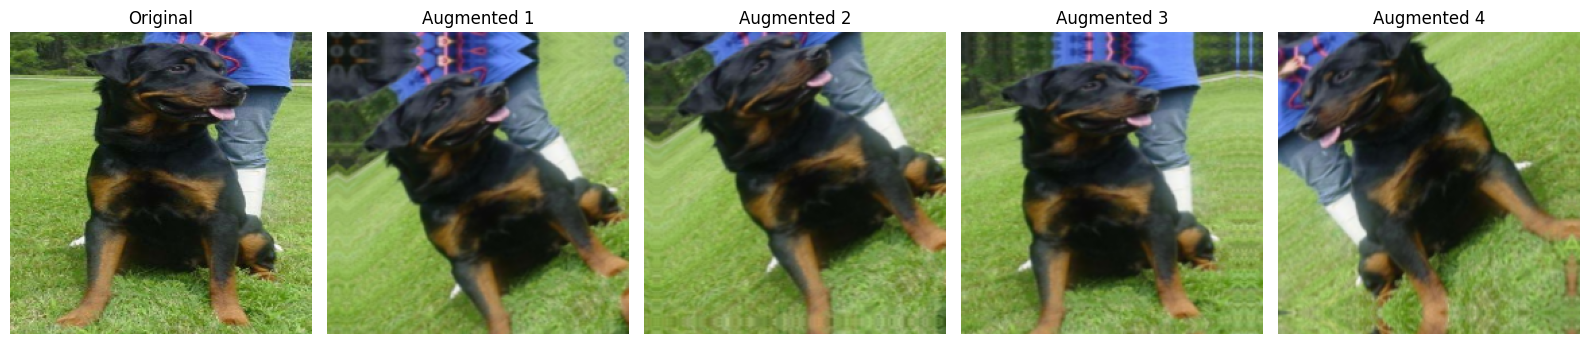

In [ ]:
# Show one original image and four augmented versions
for images, _ in train_ds.take(1):
    sample = images[0]

plt.figure(figsize=(16, 4))
plt.subplot(1, 5, 1)
plt.imshow(sample.numpy())
plt.title("Original")
plt.axis("off")

for i in range(4):
    # training=True forces the random layers to be active
    augmented = data_augmentation(tf.expand_dims(sample, 0), training=True)
    plt.subplot(1, 5, i + 2)
    plt.imshow(np.clip(augmented[0].numpy(), 0, 1))
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

---
# Question 3: Custom CNN Model

**Architecture (4 convolutional blocks):**

| Part | Layers |
|---|---|
| Input + augmentation | 224×224×3 → `data_augmentation` |
| Block 1–4 | `Conv2D` → `BatchNormalization` → `ReLU` → `MaxPooling2D` (+ `Dropout`), filters 32 → 64 → 128 → 256 |
| Head | `GlobalAveragePooling2D` → `Dense(128, relu)` → `Dropout(0.5)` → `Dense(1, sigmoid)` |

- **Batch Normalization** stabilizes and speeds up training.
- **MaxPooling** reduces spatial size and keeps the strongest features.
- **Dropout** randomly switches off neurons to fight overfitting.
- **Sigmoid** outputs a probability between 0 and 1 (here, probability of being a *dog*), so the loss is `binary_crossentropy`.
- **Global average pooling** keeps the parameter count small compared with `Flatten`.

In [ ]:
def conv_block(x, filters, dropout=0.25):
    """Conv -> BatchNorm -> ReLU -> MaxPool -> Dropout."""
    x = layers.Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(dropout)(x)
    return x

def build_custom_cnn(input_shape=(224, 224, 3)):
    """Custom CNN for binary (dog vs cat) classification."""
    inputs = layers.Input(shape=input_shape)
    x = data_augmentation(inputs)             # active only during training

    for filters in [32, 64, 128, 256]:        # 4 convolutional blocks
        x = conv_block(x, filters)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inputs, outputs, name="custom_cnn")

custom_cnn = build_custom_cnn()
custom_cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
# Compile: Adam optimizer, binary cross-entropy loss, accuracy metric
custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# Required EarlyStopping callback
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
# Train the custom CNN (EarlyStopping will stop it earlier if val_loss stops improving)
history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping],
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 93s 169ms/step - accuracy: 0.5814 - loss: 0.6716 - val_accuracy: 0.5564 - val_loss: 0.6764
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 85s 169ms/step - accuracy: 0.6221 - loss: 0.6433 - val_accuracy: 0.6487 - val_loss: 0.6426
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 84s 169ms/step - accuracy: 0.6681 - loss: 0.6140 - val_accuracy: 0.5629 - val_loss: 0.7127
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 142s 170ms/step - accuracy: 0.6862 - loss: 0.5905 - val_accuracy: 0.6267 - val_loss: 0.6528
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 141s 169ms/step - accuracy: 0.6973 - loss: 0.5850 - val_accuracy: 0.6985 - val_loss: 0.6036
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 84s 168ms/step - accuracy: 0.7097 - loss: 0.5683 - val_accuracy: 0.7123 - val_loss: 0.5648
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 84s 167ms/step - accuracy: 0.7183 - loss: 0.5593 - val_accuracy: 0.6925 - val_loss: 0.5929
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 84s 168ms/step - accuracy: 0.7259 - loss:

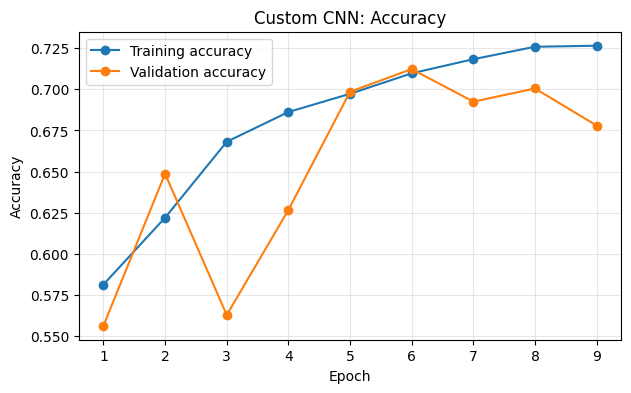

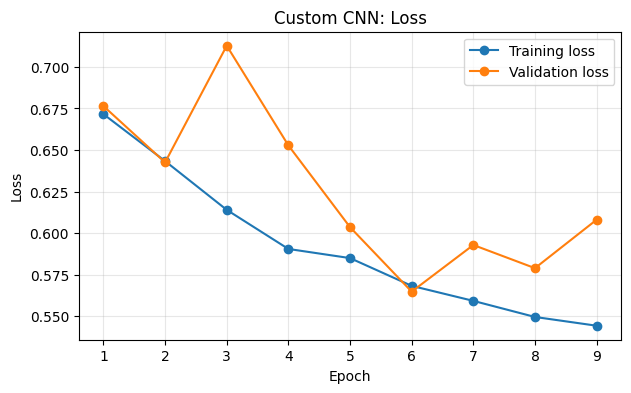

In [ ]:
def plot_history(history, title):
    """Plot training vs validation accuracy and loss."""
    acc, val_acc = history.history["accuracy"], history.history["val_accuracy"]
    loss, val_loss = history.history["loss"], history.history["val_loss"]
    epochs = range(1, len(acc) + 1)

    # Accuracy
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, acc, "o-", label="Training accuracy")
    plt.plot(epochs, val_acc, "o-", label="Validation accuracy")
    plt.title(f"{title}: Accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy")
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

    # Loss
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, loss, "o-", label="Training loss")
    plt.plot(epochs, val_loss, "o-", label="Validation loss")
    plt.title(f"{title}: Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

plot_history(history_cnn, "Custom CNN")

---
# Question 4: Transfer Learning / Feature Extraction

I use **MobileNetV2** pretrained on ImageNet as a fixed feature extractor (linear probing):

1. Load it with `weights="imagenet"` and `include_top=False` (this removes the original 1000-class classifier).
2. Freeze every backbone layer (`trainable = False`).
3. Add a new head: `GlobalAveragePooling2D → Dense(128) → Dropout → Dense(1, sigmoid)`.
4. Train **only** the new head.

**Note on preprocessing:** our data is in `[0, 1]`, but MobileNetV2 was trained on inputs in `[-1, 1]`. A `Rescaling(2.0, offset=-1.0)` layer inside the model converts `[0, 1] → [-1, 1]`, so the pretrained weights see the input range they expect.

In [ ]:
# Load pretrained backbone without its classifier and freeze it
base_mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,          # remove the original ImageNet classifier
    weights="imagenet",
)
base_mobilenet.trainable = False   # freeze ALL backbone layers

print("Backbone layers       :", len(base_mobilenet.layers))
print("Trainable backbone wts:", len(base_mobilenet.trainable_weights))   # should be 0

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Backbone layers       : 154
Trainable backbone wts: 0


In [ ]:
def build_feature_extractor():
    """Frozen MobileNetV2 backbone + new classification head."""
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(2.0, offset=-1.0)(x)           # [0,1] -> [-1,1] for MobileNetV2
    x = base_mobilenet(x, training=False)               # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)         # new head
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inputs, outputs, name="mobilenetv2_feature_extraction")

feature_model = build_feature_extractor()
feature_model.summary()

Model: "mobilenetv2_feature_extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
feature_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# Required EarlyStopping callback (re-created so it starts fresh for this experiment)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Only the new head is trained because the backbone is frozen
history_feature = feature_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping],
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 45s 79ms/step - accuracy: 0.9665 - loss: 0.0874 - val_accuracy: 0.9827 - val_loss: 0.0546
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.9737 - loss: 0.0676 - val_accuracy: 0.9870 - val_loss: 0.0421
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - accuracy: 0.9768 - loss: 0.0606 - val_accuracy: 0.9872 - val_loss: 0.0392
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 75ms/step - accuracy: 0.9794 - loss: 0.0558 - val_accuracy: 0.9842 - val_loss: 0.0479
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - accuracy: 0.9774 - loss: 0.0552 - val_accuracy: 0.9870 - val_loss: 0.0350
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - accuracy: 0.9807 - loss: 0.0510 - val_accuracy: 0.9865 - val_loss: 0.0339
Epoch 7/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - accuracy: 0.9811 - loss: 0.0479 - val_accuracy: 0.9855 - val_loss: 0.0381
Epoch 8/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 75ms/step - accuracy: 0.9822 - loss: 0.0460 - 

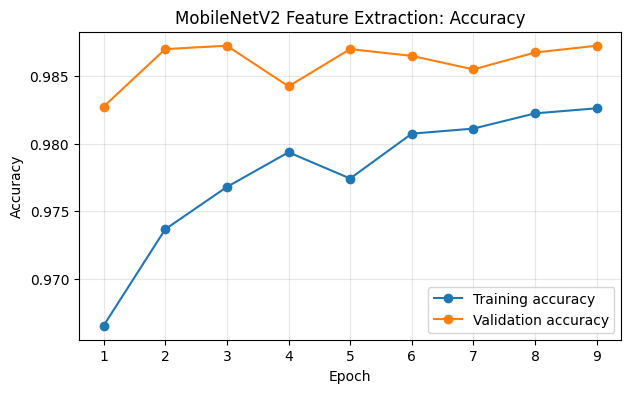

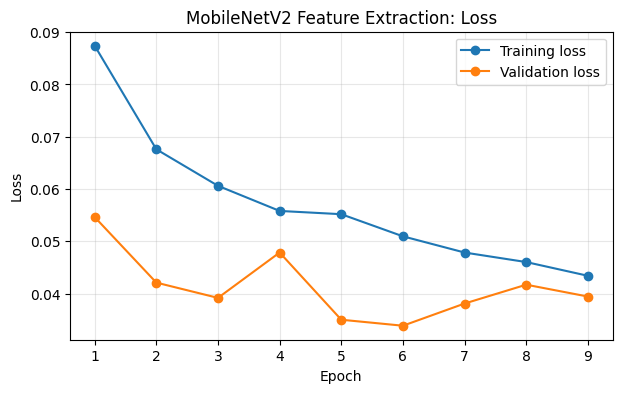

In [ ]:
plot_history(history_feature, "MobileNetV2 Feature Extraction")

### Why is freezing the backbone useful?

1. **It keeps the pretrained knowledge intact.** The early layers of an ImageNet model already detect edges, textures, fur patterns and shapes, which are exactly what dogs and cats need. Updating them with a small dataset and a randomly initialised head could destroy these useful features (the random head produces large, noisy gradients at the start).
2. **It reduces overfitting.** Only a few thousand parameters in the new head are learned instead of millions, so the model is much less likely to memorise the training set.
3. **It is much faster and cheaper.** No gradients or optimizer states are needed for the backbone, so each epoch is faster and uses less GPU memory.
4. **It works well with limited data and compute**, and gives a strong, stable baseline before attempting full fine-tuning.
5. **BatchNorm statistics stay stable**, because the backbone runs in inference mode.

---
# Question 5: Full Fine-Tuning

I use a **different** pretrained model: **EfficientNetB0**.

- Load it with ImageNet weights, without the original classifier.
- Attach a new classifier (`GlobalAveragePooling2D → Dropout → Dense(1, sigmoid)`).
- **Unfreeze all layers** so the whole network is updated.
- Use a **very small learning rate (1e-5)** so we gently adapt the pretrained weights instead of wrecking them.

**Note on preprocessing:** Keras' `EfficientNetB0` contains its own normalization and expects raw pixels in `[0, 255]`. Since our pipeline outputs `[0, 1]`, a `Rescaling(255.0)` layer converts the values back before they enter the backbone.

In [ ]:
# Load a DIFFERENT pretrained backbone and unfreeze everything
base_efficientnet = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,          # remove original classifier
    weights="imagenet",
)
base_efficientnet.trainable = True   # unfreeze ALL layers

print("Backbone layers          :", len(base_efficientnet.layers))
print("Trainable backbone wts   :", len(base_efficientnet.trainable_weights))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Backbone layers          : 238
Trainable backbone wts   : 211


In [ ]:
def build_fine_tune_model():
    """EfficientNetB0 backbone (fully trainable) + new classifier."""
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(255.0)(x)                  # [0,1] -> [0,255] expected by EfficientNetB0
    x = base_efficientnet(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)   # new classifier
    return models.Model(inputs, outputs, name="efficientnetb0_fine_tuned")

fine_tuned_model = build_fine_tune_model()
fine_tuned_model.summary()

Model: "efficientnetb0_fine_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 4,008,829 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [ ]:
fine_tuned_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # small LR for fine-tuning
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# Required EarlyStopping callback (fresh instance for this experiment)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Fine-tune the entire network
history_finetune = fine_tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping],
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 228s 386ms/step - accuracy: 0.8572 - loss: 0.3822 - val_accuracy: 0.9625 - val_loss: 0.1524
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 189s 378ms/step - accuracy: 0.9564 - loss: 0.1422 - val_accuracy: 0.9735 - val_loss: 0.0850
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 190s 381ms/step - accuracy: 0.9674 - loss: 0.0940 - val_accuracy: 0.9800 - val_loss: 0.0613
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 189s 378ms/step - accuracy: 0.9742 - loss: 0.0748 - val_accuracy: 0.9827 - val_loss: 0.0531
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 189s 378ms/step - accuracy: 0.9780 - loss: 0.0640 - val_accuracy: 0.9850 - val_loss: 0.0453
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 189s 378ms/step - accuracy: 0.9791 - loss: 0.0593 - val_accuracy: 0.9862 - val_loss: 0.0415
Epoch 7/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 189s 379ms/step - accuracy: 0.9805 - loss: 0.0521 - val_accuracy: 0.9870 - val_loss: 0.0388
Epoch 8/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 189s 379ms/step - accuracy: 0.9847 -

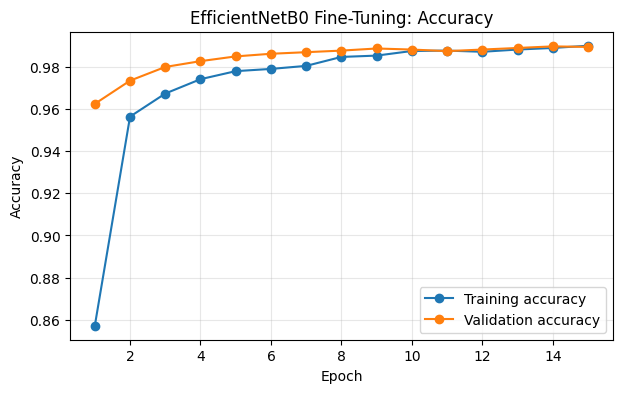

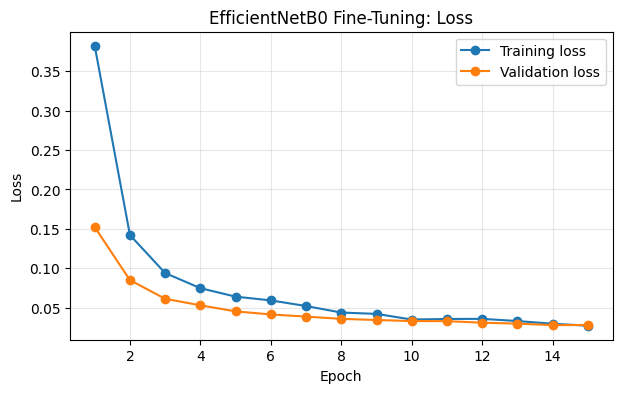

In [ ]:
plot_history(history_finetune, "EfficientNetB0 Fine-Tuning")

### Feature extraction vs. full fine-tuning

| | **Feature extraction** | **Full fine-tuning** |
|---|---|---|
| Backbone | Frozen (weights never change) | Fully trainable (all weights updated) |
| What is trained | Only the new classification head | The whole network, backbone and head |
| Trainable parameters | Few (thousands) | All (millions) |
| Learning rate | Normal (e.g. 1e-3) | Very small (e.g. 1e-5) to avoid destroying pretrained features |
| Speed / memory | Fast and light | Slower, needs more memory |
| Overfitting risk | Low | Higher, especially with little data |
| Accuracy potential | Good, limited by generic ImageNet features | Usually higher, because features adapt to the new task |
| Best when | Small dataset, little compute, task similar to ImageNet | Larger dataset, enough compute, or task that differs from ImageNet |

In short, **feature extraction reuses** the pretrained features as they are, while **fine-tuning adapts** them to the dog-vs-cat problem.

---
# Question 6: Model Comparison

For each model I evaluate on the training, validation and test sets (in inference mode, so augmentation is off), and compute precision, recall and F1 on the test set. Test labels are in a fixed order because `test_ds` is not shuffled.

In [ ]:
def get_test_predictions(model, dataset, threshold=0.5):
    """Return true labels, predicted probabilities and predicted classes for a dataset."""
    y_true = np.concatenate([y.numpy() for _, y in dataset]).ravel().astype(int)
    y_prob = model.predict(dataset, verbose=0).ravel()
    y_pred = (y_prob >= threshold).astype(int)
    return y_true, y_prob, y_pred

def summarize_model(model, name):
    """Collect all metrics needed for the comparison table."""
    train_loss, train_acc = model.evaluate(train_ds, verbose=0)
    val_loss, val_acc     = model.evaluate(val_ds, verbose=0)
    test_loss, test_acc   = model.evaluate(test_ds, verbose=0)
    y_true, _, y_pred = get_test_predictions(model, test_ds)

    return {
        "Model": name,
        "Total Parameters": model.count_params(),
        "Trainable Parameters": int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        "Training Loss": train_loss,
        "Training Accuracy": train_acc,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_acc,
        "Test Loss": test_loss,
        "Test Accuracy": test_acc,
        "Test Precision": precision_score(y_true, y_pred),
        "Test Recall": recall_score(y_true, y_pred),
        "Test F1 Score": f1_score(y_true, y_pred),
    }

In [ ]:
results = [
    summarize_model(custom_cnn,       "Custom CNN"),
    summarize_model(feature_model,    "Feature Extraction (MobileNetV2)"),
    summarize_model(fine_tuned_model, "Fine-Tuned (EfficientNetB0)"),
]

comparison_df = pd.DataFrame(results).set_index("Model").T
comparison_df

Model,Custom CNN,Feature Extraction (MobileNetV2),Fine-Tuned (EfficientNetB0)
Total Parameters,422881.000000,2.422081e+06,4.050852e+06
Trainable Parameters,421921.000000,1.640970e+05,4.008829e+06
Training Loss,0.555101,1.973949e-02,1.360828e-02
Training Accuracy,0.718422,9.927464e-01,9.963107e-01
Validation Loss,0.564835,3.387770e-02,2.791945e-02
Validation Accuracy,0.712284,9.864899e-01,9.897423e-01
Test Loss,0.556078,3.358814e-02,2.779019e-02
Test Accuracy,0.723400,9.870000e-01,9.896000e-01
Test Precision,0.780231,9.856402e-01,9.888179e-01
Test Recall,0.622000,9.884000e-01,9.904000e-01


### Discussion


**Which model performed best?**
The fine-tuned EfficientNetB0 performed best. It had the highest test accuracy (98.96%), the highest F1 score (0.9896) and the lowest test loss (0.0278). The MobileNetV2 feature-extraction model was very close behind (98.70% accuracy, F1 0.9870), a difference of only about 13 images out of 5,000. The custom CNN performed much worse (72.34% accuracy, F1 0.6922), because it had to learn all its features from scratch, while the pretrained models reused features learned from ImageNet. The custom CNN also had a low recall (0.62), so it missed many dogs.

**Which model is most computationally efficient?**
The custom CNN has the fewest total parameters (about 0.42M), but it was not the fastest to train, at about 84 seconds per epoch compared with about 38 seconds for MobileNetV2. The feature-extraction model is the most efficient overall. It trains only about 164K parameters (the new head), converges quickly, and still reaches almost the best accuracy. Full fine-tuning is the most expensive, as it updates about 4.0M parameters and is the largest model (about 4.05M total).

**Which model would I deploy in production, and why?**
I would deploy the MobileNetV2 feature-extraction model. It is only 0.26 percentage points less accurate than the fine-tuned model, but it is smaller, faster to train and cheaper to run, and MobileNetV2 is designed for mobile and edge devices. If the highest possible accuracy mattered more than speed and size, and a GPU server were available, I would choose the fine-tuned EfficientNetB0 instead. I would not deploy the custom CNN because its accuracy is far too low.

---
# Question 7: Error Analysis

`error_analysis(model, test_dataset, class_names)` does the following:

1. Predicts on the test dataset
2. Prints a **classification report**
3. Shows a **confusion matrix**
4. Displays **at least 9 misclassified images** with the actual label, predicted label and confidence

*Confidence* is the probability the model assigns to the class it predicted: `p` if it predicted class 1, else `1 - p`. To save memory, only the first 9 wrong images are kept instead of storing the whole test set.

In [ ]:
def error_analysis(model, test_dataset, class_names, num_errors=9, threshold=0.5):
    """
    Evaluate a binary classifier on a test dataset and show:
      - classification report
      - confusion matrix
      - misclassified images with actual label, predicted label and confidence
    The test dataset must NOT be shuffled and must contain normalized images.
    """
    y_true_all, y_prob_all = [], []
    wrong_images = []   # (image, actual, predicted, confidence)

    # 1) Predict batch by batch
    for images, labels in test_dataset:
        probs = model.predict(images, verbose=0).ravel()
        preds = (probs >= threshold).astype(int)
        actual = labels.numpy().ravel().astype(int)

        y_true_all.extend(actual)
        y_prob_all.extend(probs)

        # keep only the first `num_errors` wrong images (saves memory)
        for i in np.where(preds != actual)[0]:
            if len(wrong_images) < num_errors:
                confidence = probs[i] if preds[i] == 1 else 1 - probs[i]
                wrong_images.append((images[i].numpy(), actual[i], preds[i], confidence))

    y_true = np.array(y_true_all)
    y_pred = (np.array(y_prob_all) >= threshold).astype(int)

    # 2) Classification report
    print("Classification Report")
    print("=" * 60)
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # 3) Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap="Blues", values_format="d")
    plt.title("Confusion Matrix")
    plt.show()

    # 4) Misclassified images
    total_errors = int((y_true != y_pred).sum())
    print(f"Total misclassified images: {total_errors} / {len(y_true)}")

    if wrong_images:
        cols = 3
        rows = int(np.ceil(len(wrong_images) / cols))
        plt.figure(figsize=(12, 4 * rows))
        for idx, (img, actual, pred, conf) in enumerate(wrong_images):
            plt.subplot(rows, cols, idx + 1)
            plt.imshow(np.clip(img, 0, 1))
            plt.title(f"Actual: {class_names[actual]}\nPredicted: {class_names[pred]}\nConfidence: {conf:.2%}",
                      color="red")
            plt.axis("off")
        plt.suptitle("Misclassified Images", fontsize=16)
        plt.tight_layout()
        plt.show()
    else:
        print("No misclassified images found.")

Classification Report
              precision    recall  f1-score   support

        cats     0.9904    0.9888    0.9896      2500
        dogs     0.9888    0.9904    0.9896      2500

    accuracy                         0.9896      5000
   macro avg     0.9896    0.9896    0.9896      5000
weighted avg     0.9896    0.9896    0.9896      5000



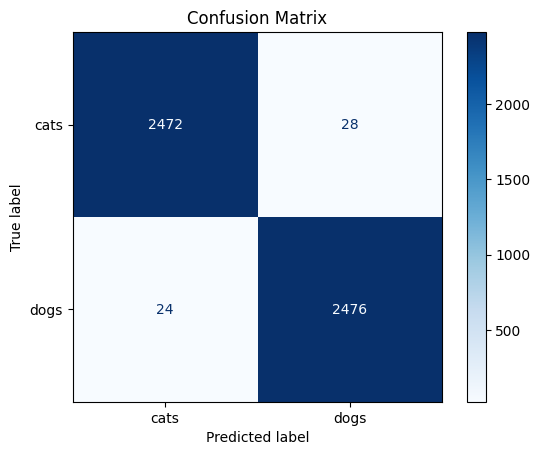

Total misclassified images: 52 / 5000


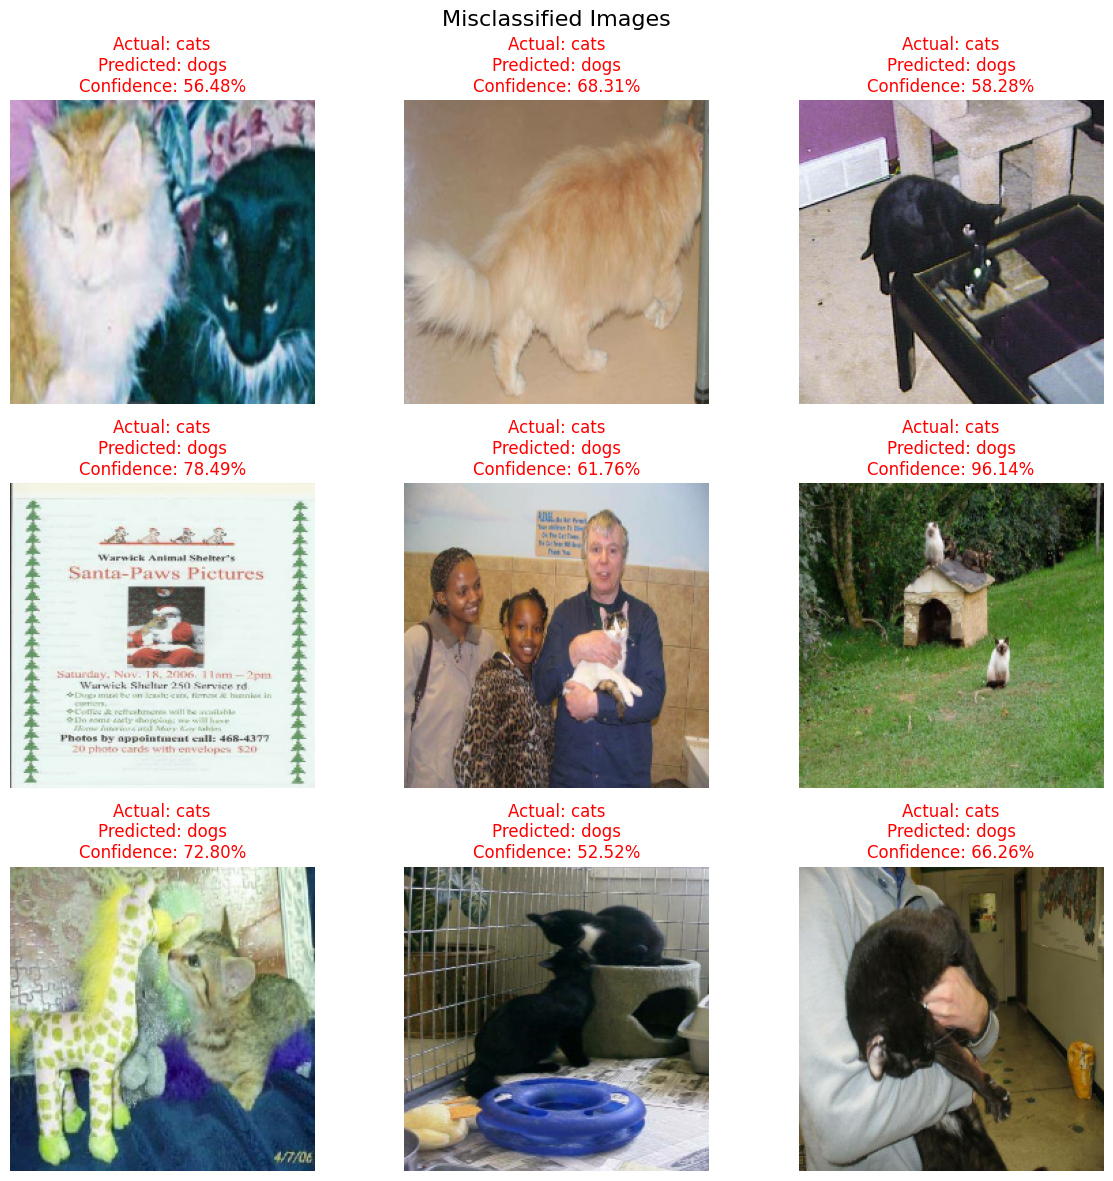

In [ ]:
# Run the error analysis on the best model (change this to custom_cnn or feature_model to compare)
error_analysis(fine_tuned_model, test_ds, class_names)

### Observations

The fine-tuned EfficientNetB0 misclassified 52 of 5,000 test images (about 1%), with errors split almost evenly between the two classes (about 28 cats predicted as dogs and 24 dogs predicted as cats), so the model shows no strong bias. The 9 misclassified images displayed are all cats, because the test set is not shuffled and the first errors encountered come from the cat folder.

Looking at these images, the errors come mostly from difficult or ambiguous inputs. Several cats are dark or black, partly hidden, or in cluttered scenes (a cage, a dark table, being held by a person). In other images the cat is small or far away, or other objects distract the model, such as people, a toy giraffe, or a doghouse. One image is a printed flyer rather than a real photo of an animal, which suggests some label noise in the dataset. Another has strongly distorted colors.

Most wrong predictions had low to moderate confidence (about 52% to 78%, average around 68%), meaning the model was uncertain on these hard cases and not confidently wrong. The one exception was a 96% prediction on an image of small, distant cats near a doghouse. Overall, the errors are understandable, and the model could be improved with more training examples of dark cats and cluttered scenes, and by cleaning mislabeled images.

---
# ✅ Summary

- Built a clean data pipeline (resize, 80/20 split, normalization, prefetch)
- Applied augmentation during training only
- Trained a custom CNN, a feature-extraction model and a fully fine-tuned model, each with the required `EarlyStopping` callback
- Compared all three models on loss, accuracy, precision, recall, F1 and parameter count
- Analysed the errors with a reusable function